# Multi-filter bot detection for incentivized online surveys

This notebook implements the 11-filter pipeline described in

> Ruger, A., Abdalazeem, M., Christofa, E., & Oke, J. (2026). *Explainable Data-Driven Multi-filter Framework for Bot Detection in Incentivized Online Surveys.* Data Science for Transportation, 8, 21. https://doi.org/10.1007/s42421-026-00158-4

It takes a survey export with the response metadata that platforms such as Qualtrics record automatically (risk scores, duplicate flags, page timing, click counts, browser and device details), applies the filters in the order used in the paper, and reports how many responses each filter removes.

**How to use it on your own survey**

1. Export your responses as CSV, including the embedded metadata fields (in Qualtrics: *RelevantID*, *reCAPTCHA*, *Response Quality*, page *Timing* questions, and the *Browser Meta Info* question).
2. Point `DATA_PATH` in the configuration cell at your file.
3. If your column names differ from the Qualtrics defaults, change them in `COLUMNS`. Any filter whose columns are missing is skipped and reported, so the notebook runs on partial exports too.
4. Adjust `THRESHOLDS` if needed. The defaults are the values used in the paper.
5. Run all cells. The cleaned data and a step-by-step summary table are written to `OUTPUT_DIR`.

**About the outputs saved in this notebook.** The study's survey data cannot be shared because of participant privacy restrictions. The outputs shown here were produced by running the notebook on the full study export (12,020 responses), with `DATA_PATH` pointing to that private file. No individual responses are displayed anywhere in the notebook; only counts and summary figures. Running the notebook on the included synthetic example (`examples/synthetic_survey_export.csv`) produces different, smaller numbers.

## 1. Setup

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 80)

## 2. Configuration

Everything that depends on your survey lives in this cell: the input file, the output folder, the column names, and the filter thresholds.

In [2]:
# ---- Input and output -------------------------------------------------------
# Set the SURVEY_EXPORT environment variable, or edit the default path below.
DATA_PATH = Path(os.environ.get("SURVEY_EXPORT", "../examples/synthetic_survey_export.csv"))
OUTPUT_DIR = Path(os.environ.get("BOT_OUTPUT_DIR", "../outputs"))

# ---- Column names (Qualtrics defaults) --------------------------------------
# Timing and click-count columns are found automatically by their suffixes.
COLUMNS = {
    "recaptcha":      "Q_RecaptchaScore",            # Google reCAPTCHA v3 score, 0 (bot) to 1 (human)
    "fraud":          "Q_RelevantIDFraudScore",      # Qualtrics RelevantID fraud score, 0 to 130
    "ambiguous_text": "Q_AmbiguousTextPresent",      # Qualtrics Response Quality flag for filler text
    "dup_platform":   "Q_RelevantIDDuplicate",       # RelevantID duplicate flag
    "dup_respondent": "Q_DuplicateRespondent",       # Qualtrics duplicate respondent flag
    "ip":             "IPAddress",
    "browser":        "Q2_Browser (Click to write the question text - Browser)",
    "version":        "Q2_Version (Click to write the question text - Version)",
    "os":             "Q2_Operating System (Click to write the question text - Operating System)",
    "resolution":     "Q2_Resolution (Click to write the question text - Resolution)",
    "device":         "Q_DeviceType",                # "Desktop" or "Mobile"; derived from the OS if missing
    "duration":       "Duration (in seconds)",
}
PAGE_SUBMIT_SUFFIX = "Page Submit (Timing - Page Submit)"
CLICK_COUNT_SUFFIX = "Click Count (Timing - Click Count)"
FIRST_PAGE_SUBMIT = "Q3_Page Submit (Timing - Page Submit)"   # page that holds only the reCAPTCHA check

# ---- Filter thresholds (values used in the paper) --------------------------
THRESHOLDS = {
    "recaptcha_min": 0.6,        # remove responses with a reCAPTCHA score below this
    "fraud_max": 30,             # remove responses with a fraud score above this
    "page_quantiles": (0.05, 0.95),
    "page_min_seconds": 15,      # floor for the lower per-page bound (not applied to the reCAPTCHA page)
    "duration_quantiles": (0.05, 0.95),
    "desktop_min_width": 600,    # a desktop reporting a narrower viewport than this is implausible
    "desktop_min_height": 600,
    "mobile_max_width": 1200,    # a phone reporting a wider viewport than this is implausible
    "desktop_tiny_width": 300,
}

## 3. Load the data

Only the shape of the file and a check of the expected columns are printed. No responses are displayed.

In [3]:
df_raw = pd.read_csv(DATA_PATH, low_memory=False)

PAGE_SUBMIT_COLS = [c for c in df_raw.columns if c.endswith(PAGE_SUBMIT_SUFFIX)]
CLICK_COUNT_COLS = [c for c in df_raw.columns if c.endswith(CLICK_COUNT_SUFFIX)]

# Derive the device type from the operating system when the export does not carry it.
if COLUMNS["device"] not in df_raw.columns and COLUMNS["os"] in df_raw.columns:
    os_str = df_raw[COLUMNS["os"]].astype(str)
    df_raw[COLUMNS["device"]] = np.where(os_str.str.contains("Android|iOS|iPhone|iPad", case=False), "Mobile",
                                np.where(os_str.str.contains("Windows|Mac|Linux|Chrom|Ubuntu|Fedora|Mint", case=False),
                                         "Desktop", np.nan))

print(f"File: {DATA_PATH.name}")
print(f"Responses: {len(df_raw):,}   Columns: {df_raw.shape[1]}")
print(f"Page-timing columns found: {len(PAGE_SUBMIT_COLS)}   Click-count columns found: {len(CLICK_COUNT_COLS)}")
missing = [k for k, c in COLUMNS.items() if c not in df_raw.columns]
print("Missing configured columns:", missing if missing else "none")

File: 18aa095e-processed_survey_data_full.csv
Responses: 12,020   Columns: 74
Page-timing columns found: 4   Click-count columns found: 4
Missing configured columns: none


## 4. Pipeline helpers

Each filter is a function that takes a DataFrame and returns the rows to keep. `run_filter` applies it, records what was removed, and carries the survivors to the next step. A filter whose columns are not in the export is skipped rather than failing.

In [4]:
RESULTS = []

def has_columns(df, *keys):
    return all(COLUMNS[k] in df.columns for k in keys)

def run_filter(df, name, category, criterion, fn, requires=()):
    n_before = len(df)
    if requires and not has_columns(df, *requires):
        print(f"Skipped '{name}': column(s) not in export: {[COLUMNS[k] for k in requires if COLUMNS[k] not in df.columns]}")
        return df
    kept = fn(df)
    removed = n_before - len(kept)
    RESULTS.append({
        "category": category,
        "filter": name,
        "criterion": criterion,
        "removed": removed,
        "remaining": len(kept),
        "removed_pct_of_stage": round(100 * removed / n_before, 2) if n_before else 0.0,
        "removed_pct_cumulative": round(100 * (N_RAW - len(kept)) / N_RAW, 2),
    })
    print(f"{name:<28} removed {removed:>6,}   remaining {len(kept):>7,}")
    return kept.copy()

def parse_resolution(value):
    # "1920x1080" -> (1920, 1080); anything else -> (None, None)
    try:
        w, h = (int(v) for v in str(value).lower().split("x")[:2])
        return w, h
    except (ValueError, TypeError):
        return None, None

N_RAW = len(df_raw)
df = df_raw.copy()

## 5. Platform-generated risk signals

The survey platform scores every session while it is being completed. These three filters use those scores as they are exported, without any modification.

In [5]:
def low_recaptcha(df):
    score = pd.to_numeric(df[COLUMNS["recaptcha"]], errors="coerce")
    return df[score >= THRESHOLDS["recaptcha_min"]]

def high_fraud_score(df):
    score = pd.to_numeric(df[COLUMNS["fraud"]], errors="coerce")
    return df[score <= THRESHOLDS["fraud_max"]]

def response_ambiguity(df):
    flag = df[COLUMNS["ambiguous_text"]].astype(str).str.lower().eq("true")
    return df[~flag]

df = run_filter(df, "Low reCAPTCHA score", "Platform risk signals",
                f"score < {THRESHOLDS['recaptcha_min']}", low_recaptcha, requires=("recaptcha",))
df = run_filter(df, "High fraud score", "Platform risk signals",
                f"score > {THRESHOLDS['fraud_max']}", high_fraud_score, requires=("fraud",))
df = run_filter(df, "Response ambiguity", "Platform risk signals",
                "platform flag is True", response_ambiguity, requires=("ambiguous_text",))

Low reCAPTCHA score          removed  6,082   remaining   5,938
High fraud score             removed  2,658   remaining   3,280
Response ambiguity           removed     42   remaining   3,238


## 6. Identity and duplicates

A response is removed if the platform flagged it as a duplicate, or if the same IP address appears with the same browser, version, operating system, and screen resolution more than once. A shared IP address alone is not grounds for removal, because people in offices, libraries, or households legitimately share one.

In [6]:
def duplicate_identity(df):
    keep = pd.Series(True, index=df.index)
    for key in ("dup_platform", "dup_respondent"):
        if COLUMNS[key] in df.columns:
            keep &= ~df[COLUMNS[key]].astype(str).str.lower().eq("true")
    fingerprint = [COLUMNS[k] for k in ("ip", "browser", "version", "os", "resolution") if COLUMNS[k] in df.columns]
    if COLUMNS["ip"] in df.columns and len(fingerprint) > 1:
        group_size = df[keep].groupby(fingerprint, dropna=True)[COLUMNS["ip"]].transform("size")
        keep.loc[group_size.index] &= group_size.isna() | (group_size <= 1)
    return df[keep]

df = run_filter(df, "Duplicate identity", "Identity",
                "platform duplicate flag, or same IP with identical device fingerprint", duplicate_identity)

Duplicate identity           removed    859   remaining   2,379


## 7. Interaction patterns

Completing a multi-page form leaves traces: navigation clicks, and a plausible amount of time on each page. These filters remove sessions with no clicks at all, sessions whose page-advance timing is identical to another session's (automated replay), and sessions whose per-page or total times fall in the extreme tails.

The lower per-page bound is the 5th percentile, raised to `page_min_seconds` when the percentile is lower. The first page is exempt from that floor because it contains only the reCAPTCHA check, which takes a few seconds for everyone.

In [7]:
def zero_clicks(df):
    clicks = df[CLICK_COUNT_COLS].apply(pd.to_numeric, errors="coerce")
    recorded_on_every_page = clicks.notna().all(axis=1)   # a missing count means no click was recorded on that page
    return df[recorded_on_every_page & (clicks.sum(axis=1) > 0)]

def duplicate_temporal_pattern(df):
    times = df[PAGE_SUBMIT_COLS].apply(pd.to_numeric, errors="coerce").fillna(0)
    # Pass 1: timing vectors rounded up to the second, plus sessions that paused only on the first page
    vec = times.apply(np.ceil).astype(int)
    replayed = vec.duplicated(keep=False)
    first_page_only = (vec.iloc[:, 0] > 0) & (vec.iloc[:, 1:] == 0).all(axis=1)
    kept = df[~(replayed | first_page_only)]
    # Pass 2: timing vectors rounded to the nearest second
    vec = times.loc[kept.index].round().astype(int)
    return kept[~vec.duplicated(keep=False)]

def extreme_page_duration(df):
    lo_q, hi_q = THRESHOLDS["page_quantiles"]
    times = df[PAGE_SUBMIT_COLS].apply(pd.to_numeric, errors="coerce").fillna(0)
    keep = pd.Series(True, index=df.index)
    for col in PAGE_SUBMIT_COLS:
        lo, hi = times[col].quantile(lo_q), times[col].quantile(hi_q)
        if col != FIRST_PAGE_SUBMIT:
            lo = max(lo, THRESHOLDS["page_min_seconds"])
        keep &= (times[col] > lo) & (times[col] < hi)
    return df[keep]

def extreme_survey_duration(df):
    lo_q, hi_q = THRESHOLDS["duration_quantiles"]
    dur = pd.to_numeric(df[COLUMNS["duration"]], errors="coerce")
    lo, hi = dur.quantile(lo_q), dur.quantile(hi_q)
    return df[(dur > lo) & (dur < hi)]

if CLICK_COUNT_COLS:
    df = run_filter(df, "Zero clicks", "Interaction patterns", "zero clicks in total, or no click count recorded on a page", zero_clicks)
if PAGE_SUBMIT_COLS:
    df = run_filter(df, "Duplicate temporal pattern", "Interaction patterns",
                    "page timing identical to another session, or first page only", duplicate_temporal_pattern)
    df = run_filter(df, "Extreme page duration", "Interaction patterns",
                    f"outside the {int(THRESHOLDS['page_quantiles'][0]*100)}th to {int(THRESHOLDS['page_quantiles'][1]*100)}th "
                    f"percentile on any page (floor {THRESHOLDS['page_min_seconds']} s)", extreme_page_duration)
df = run_filter(df, "Extreme survey duration", "Interaction patterns",
                f"outside the {int(THRESHOLDS['duration_quantiles'][0]*100)}th to {int(THRESHOLDS['duration_quantiles'][1]*100)}th percentile",
                extreme_survey_duration, requires=("duration",))

Zero clicks                  removed    568   remaining   1,811
Duplicate temporal pattern   removed     46   remaining   1,765
Extreme page duration        removed  1,056   remaining     709
Extreme survey duration      removed     72   remaining     637


## 8. Device consistency

The browser's user agent string and the reported screen size should agree with each other. These filters remove unparsable or implausible screen sizes, browser and operating system pairs that cannot occur (Safari on Android, for example), and user agents whose parts are individually plausible but inconsistent together.

In [8]:
def invalid_resolution(df):
    wh = df[COLUMNS["resolution"]].map(parse_resolution)
    w = wh.map(lambda t: t[0]).astype("float"); h = wh.map(lambda t: t[1]).astype("float")
    desktop = df[COLUMNS["device"]].astype(str).str.lower().eq("desktop")
    bad = w.isna() | h.isna() | (w <= 0) | (h <= 0)
    bad |= desktop & ((w < THRESHOLDS["desktop_min_width"]) | (h < THRESHOLDS["desktop_min_height"]) | ((w < 800) & (h < 900)))
    return df[~bad]

def software_incompatibility(df):
    b = df[COLUMNS["browser"]].astype(str); o = df[COLUMNS["os"]].astype(str)
    v = df[COLUMNS["version"]].astype(str); d = df[COLUMNS["device"]].astype(str).str.lower()
    os_mobile = o.str.contains("Android|iOS|iPhone|iPad", case=False, na=False)
    os_desktop = o.str.contains("Windows|Mac|macOS|Linux|ChromeOS", case=False, na=False)
    in_app = ["Facebook", "Instagram", "TikTok", "Pinterest", "Snapchat", "LinkedIn", "WeChat"]
    bad = (
        (b.eq("Mobile Safari") & ~o.eq("iOS"))
        | (b.eq("Safari") & ~o.isin(["Mac OS", "iOS"]))
        | (b.eq("Chrome WebView") & ~o.eq("Android"))
        | (b.eq("Samsung Internet") & ~o.eq("Android"))
        | (b.eq("Silk") & ~o.eq("Android"))
        | (b.isin(in_app) & ~o.isin(["iOS", "Android"]))
        | (b.isin(["Chrome iOS", "Firefox iOS", "Edge iOS"]) & ~o.eq("iOS"))
        | (d.eq("desktop") & os_mobile) | (d.eq("mobile") & os_desktop)
    )
    # Brave reports either a Chromium-style four-part version or a Brave-style "1.x.y" version
    brave = b.str.strip().str.lower().eq("brave")
    brave_ok = v.str.match(r"^\d+\.\d+\.\d+\.\d+$") | v.str.match(r"^1\.\d+\.\d+$")
    bad |= brave & ~brave_ok
    return df[~bad]

def user_agent_inconsistency(df):
    v = df[COLUMNS["version"]]; d = df[COLUMNS["device"]].astype(str).str.lower()
    w = df[COLUMNS["resolution"]].map(parse_resolution).map(lambda t: t[0]).astype("float")
    bad = v.isna() | v.astype(str).str.strip().str.lower().isin(["", "nan", "none"])
    bad |= d.eq("mobile") & (w >= THRESHOLDS["mobile_max_width"])
    bad |= d.eq("desktop") & (w > 0) & (w < THRESHOLDS["desktop_tiny_width"])
    return df[~bad]

df = run_filter(df, "Invalid resolution", "Device consistency",
                "unparsable, zero, or implausible for the device type", invalid_resolution, requires=("resolution", "device"))
df = run_filter(df, "Software incompatibility", "Device consistency",
                "browser, OS, and device combinations that cannot occur", software_incompatibility,
                requires=("browser", "os", "version", "device"))
df = run_filter(df, "User agent inconsistency", "Device consistency",
                "missing version, or viewport width inconsistent with device type", user_agent_inconsistency,
                requires=("version", "resolution", "device"))

Invalid resolution           removed      3   remaining     634


Software incompatibility     removed     12   remaining     622
User agent inconsistency     removed      2   remaining     620


## 9. Results

In [9]:
results = pd.DataFrame(RESULTS)
print(f"Received: {N_RAW:,}    Passed all filters: {len(df):,}    Removed: {100 * (N_RAW - len(df)) / N_RAW:.1f}%")
results.style.hide(axis="index").format({"removed": "{:,}", "remaining": "{:,}"})

Received: 12,020    Passed all filters: 620    Removed: 94.8%


category,filter,criterion,removed,remaining,removed_pct_of_stage,removed_pct_cumulative
Platform risk signals,Low reCAPTCHA score,score < 0.6,"6,082","5,938",50.600000,50.600000
Platform risk signals,High fraud score,score > 30,"2,658","3,280",44.760000,72.710000
Platform risk signals,Response ambiguity,platform flag is True,42,"3,238",1.280000,73.060000
Identity,Duplicate identity,"platform duplicate flag, or same IP with identical device fingerprint",859,"2,379",26.530000,80.210000
Interaction patterns,Zero clicks,"zero clicks in total, or no click count recorded on a page",568,"1,811",23.880000,84.930000
Interaction patterns,Duplicate temporal pattern,"page timing identical to another session, or first page only",46,"1,765",2.540000,85.320000
Interaction patterns,Extreme page duration,outside the 5th to 95th percentile on any page (floor 15 s),"1,056",709,59.830000,94.100000
Interaction patterns,Extreme survey duration,outside the 5th to 95th percentile,72,637,10.160000,94.700000
Device consistency,Invalid resolution,"unparsable, zero, or implausible for the device type",3,634,0.470000,94.730000
Device consistency,Software incompatibility,"browser, OS, and device combinations that cannot occur",12,622,1.890000,94.830000


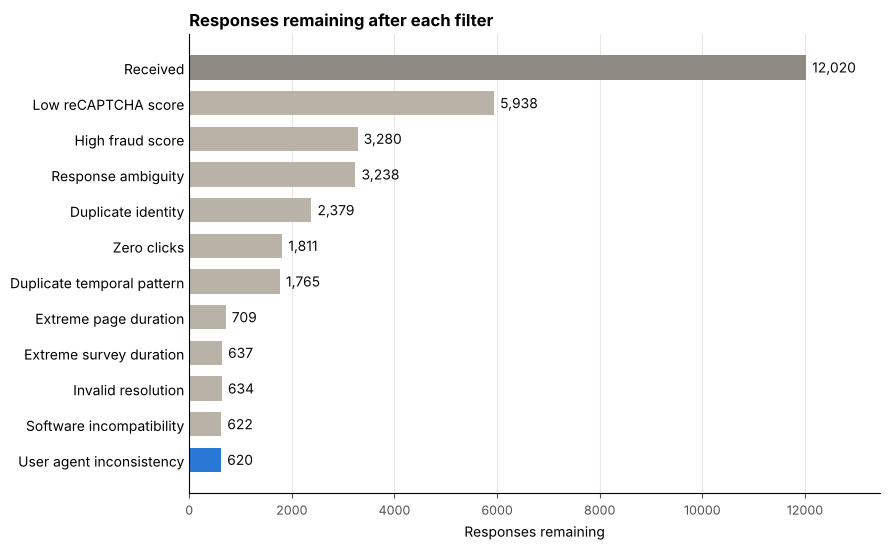

In [10]:
stages = ["Received"] + results["filter"].tolist()
remaining = [N_RAW] + results["remaining"].tolist()
category = ["Received"] + results["category"].tolist()
palette = {"Received": "#8E8A83", "Platform risk signals": "#B8B2A7", "Identity": "#B8B2A7",
           "Interaction patterns": "#B8B2A7", "Device consistency": "#B8B2A7"}
colors = [palette[c] for c in category]; colors[-1] = "#2A78D6"

fig, ax = plt.subplots(figsize=(9, 5.6))
y = np.arange(len(stages))[::-1]
ax.barh(y, remaining, color=colors, height=0.68)
for yi, val in zip(y, remaining):
    ax.text(val + N_RAW * 0.01, yi, f"{val:,}", va="center", fontsize=10, color="#0B0B0B")
ax.set_yticks(y, stages, fontsize=10)
ax.set_xlim(0, N_RAW * 1.12)
ax.set_xlabel("Responses remaining", fontsize=10)
ax.set_title("Responses remaining after each filter", loc="left", fontsize=12, fontweight="bold")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.tick_params(axis="x", labelsize=9, colors="#52514E"); ax.tick_params(axis="y", length=0)
ax.xaxis.grid(True, color="#E9E7E2"); ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 10. Save the outputs

Two files are written to `OUTPUT_DIR`: the responses that passed every filter, and the summary table above.

In [11]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(OUTPUT_DIR / "survey_responses_cleaned.csv", index=False)
results.to_csv(OUTPUT_DIR / "filter_summary.csv", index=False)
print(f"Wrote {len(df):,} cleaned responses and the summary table to {OUTPUT_DIR}/")

Wrote 620 cleaned responses and the summary table to ../outputs/
